<a href="https://colab.research.google.com/github/sabbirpuspo/PGCB-Demand-Aware-Smart-Grid-Optimization/blob/main/PGCB_IEEE_Final_Validation_2024_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PGCB IEEE Paper | Final Temporal Validation (2024)

**Paper title:** *An Intelligent Demand-Aware Optimization Framework for Peak Load Management and Load-Shedding Mitigation in Smart Grids*

## Purpose and frozen research protocol

This single Colab notebook performs the **remaining chronological validation** of our established forecasting-plus-scheduling pipeline using calendar year **2024**. It reuses the mathematical specification and solver settings from the previously executed `PGCB_Phase5_Feasibility_Independent_Optimization.ipynb`, without selecting a new optimizer or tuning any settings on the 2024 outcomes.

- **PGCB data:** UCI Machine Learning Repository dataset 1175, DOI [10.24432/C59P6V](https://doi.org/10.24432/C59P6V), CC BY 4.0. The official Excel workbook is downloaded automatically if missing from Google Drive.
- **Ridge training:** eligible observations before 2022-07-01, with *unchanged* `alpha=100`, 14 demand-lag/calendar features, training-median imputation and standard scaling.
- **Historical uncertainty calibration:** 2022-07-01 through 2022-12-31, with *unchanged* Q90/Q95/Q99 hourly/global error margins and 50% hourly weighting.
- **2023:** prior development / exploratory period, **not** the final evaluation in this notebook.
- **2024:** later chronological **evaluation**; this period was excluded from Phase 5 training, calibration and model selection. The notebook never uses realized target-hour demand while planning shifts.
- **Flexible-load scenarios:** 5%, 10%, and 15% of each actual hour's demand, assumed rather than observed.
- **Candidate:** `WaterfillQ90` — manuscript working label **UAD-WF (Q90)**. Compare with independently chosen-hour robust LP, exact-shift-MWh robust/nominal MILP, and conservative Q95/Q99 sensitivities.
- **Key measurements:** mean/median simulated peak reduction, ex-post feasibility, moved daily MWh, risk of worsening a day's peak, forecast error, and paired weekly-block uncertainty intervals.

**No causal or operational claims:** PGCB does not report real flexible-load capability or hour-by-hour dispatchable grid reserve. Scheduling results are counterfactual simulated outcomes; there is no demonstrated actual reduction in load shedding, power consumption or carbon emissions. The name UAD-WF does not by itself demonstrate mathematical novelty. The UCI extension also makes our forecasting protocol **not directly comparable** to the 2025 journal's published MAPE without separate benchmarking.

**Reproducibility:** Every code cell has a preceding Markdown explanation. Outputs are written in a new Google Drive folder under `MyDrive/PGCB_Demand_Optimization/runs/ieee_final_2024_*` and are never overwritten. Publication-oriented plots are exported as both **600-DPI PNG** and **vector PDF**, with the dataset hash, software versions and parameters saved in JSON.

**How to run:** Upload this notebook in Colab, then choose **Runtime > Run all**. A CPU runtime is sufficient. The run may take time because the independent-hour MILP is solved separately for every eligible day and flexibility level. Preserve all generated CSV, JSON and figures for your manuscript and GitHub audit trail.


## 1. Runtime and libraries

Import the scientific libraries, including SciPy's HiGHS-based LP and MILP solvers. The exact-MWh independent-hour comparison uses binary decisions to ensure that any hour either donates or receives shifted demand, not both.

In [ ]:
import hashlib
import io
import json
import os
import platform
import shutil
import sys
import time
import uuid
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import scipy
import sklearn
from scipy.optimize import Bounds, LinearConstraint, linprog, milp
from scipy.sparse import lil_matrix
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

IS_COLAB = 'google.colab' in sys.modules
SEED = 20261107
np.random.seed(SEED)
print('Runtime:', 'Google Colab' if IS_COLAB else 'local Python')
print('Python', platform.python_version(), '| pandas', pd.__version__,
      '| SciPy', scipy.__version__, '| scikit-learn', sklearn.__version__)

Runtime: Google Colab
Python 3.13.16 | pandas 2.2.3 | SciPy 1.16.3 | scikit-learn 1.6.1


## 2. Frozen experiment settings and Google Drive

Use exactly the Phase 5 forecasting, Q90/Q95/Q99 margin, solver and flexibility settings. Only the evaluation period changes from 2023 to 2024. A timestamp-plus-random-suffix folder prevents overwriting previous runs. The reported 600-DPI settings affect final figure exports, not the optimization calculations.


In [ ]:
USE_GOOGLE_DRIVE = True
FLEX_LEVELS = (0.05, 0.10, 0.15)
MARGIN_QUANTILES = (0.90, 0.95, 0.99)
HOUR_MARGIN_WEIGHT = 0.50
DOMAIN_FLOOR_MW = 1000.0
DEMAND_LIMITS_MW = (DOMAIN_FLOOR_MW, 30000.0)
GENERATION_LIMITS_MW = (0.0, 30000.0)
MIP_TIME_LIMIT_SECONDS = 2.0
MIP_RELATIVE_GAP = 1e-4
BOOTSTRAP_REPLICATES = 2000
DATASET_FILENAME = 'PGCB_date_power_demand.xlsx'
UCI_ARCHIVE_URL = (
    'https://archive.ics.uci.edu/static/public/1175/'
    'pgcb%2Bhourly%2Bgeneration%2Bdataset%2B%28bangladesh%29.zip'
)

if IS_COLAB and USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = Path('/content/drive/MyDrive/PGCB_Demand_Optimization')
elif IS_COLAB:
    PROJECT_DIR = Path('/content/PGCB_Demand_Optimization')
else:
    PROJECT_DIR = Path(os.environ.get('PGCB_PROJECT_DIR', '/mnt/data/PGCB_Demand_Optimization'))
DATA_DIR = PROJECT_DIR / 'data'
RUN_ID = ('ieee_final_2024_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
          + '_' + uuid.uuid4().hex[:6])
OUT_DIR = PROJECT_DIR / 'runs' / RUN_ID
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=False)
print('Run ID:', RUN_ID)
print('Output directory:', OUT_DIR)

Mounted at /content/drive
Run ID: ieee_final_2024_20261108T042536Z_4eecbb
Output directory: /content/drive/MyDrive/PGCB_Demand_Optimization/runs/ieee_final_2024_20261108T042536Z_4eecbb


## 3. Load the original workbook with provenance

Download the official UCI archive only if no cached workbook exists. Record the original file's SHA-256 fingerprint so a reviewer can identify the exact source version. For local verification only, `PGCB_LOCAL_XLSX` may specify an existing workbook. The original file is read-only and is never modified.

In [ ]:
DATA_PATH = DATA_DIR / DATASET_FILENAME
local_override = os.environ.get('PGCB_LOCAL_XLSX') if not IS_COLAB else None
if local_override:
    DATA_PATH = Path(local_override)

if not DATA_PATH.exists():
    print('Cached workbook not found; downloading the original UCI archive...')
    response = requests.get(UCI_ARCHIVE_URL, timeout=180)
    response.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
        members = [name for name in archive.namelist()
                   if name.lower().endswith('pgcb_date_power_demand.xlsx')]
        if len(members) != 1:
            raise RuntimeError(f'Expected exactly one PGCB workbook; found {members}')
        staged = DATA_DIR / (DATASET_FILENAME + '.partial')
        try:
            with archive.open(members[0]) as original, staged.open('wb') as copy:
                shutil.copyfileobj(original, copy)
            staged.replace(DATA_PATH)
        finally:
            staged.unlink(missing_ok=True)

assert DATA_PATH.exists() and DATA_PATH.stat().st_size > 1000
SOURCE_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
raw = pd.read_excel(DATA_PATH, engine='openpyxl',
                    usecols=['datetime', 'demand_mw', 'generation_mw', 'load_shedding'])
print('Loaded source rows:', len(raw))
print('Source checksum:', SOURCE_SHA256)

Loaded source rows: 92650
Source checksum: cd10a95b98033594b70ff176d69e9feaa2ade5f43b8ae4e5640a0f9deabc9da1


## 4. Build the conservative hourly dataset through 2024

Reuse Phase 5 preprocessing: discard ambiguous duplicated timestamps and off-hour measurements, retain plausible demand/generation ranges, and analyze only days with exactly 24 unique hourly readings. **Extend only the date scope through the end of 2024**. This eligibility filter can introduce selection bias; report the retained-day count and do not imply the sample covers every operating day of the Bangladesh grid.


In [ ]:
working = raw.copy()
working['datetime'] = pd.to_datetime(working['datetime'], errors='coerce')
for field in ('demand_mw', 'generation_mw', 'load_shedding'):
    working[field] = pd.to_numeric(working[field], errors='coerce')

scope = working.loc[working['datetime'].lt(pd.Timestamp('2025-01-01'))].copy()
duplicate_group = scope['datetime'].duplicated(keep=False)
on_hour = scope['datetime'].dt.minute.eq(0) & scope['datetime'].dt.second.eq(0)
valid_demand = scope['demand_mw'].between(*DEMAND_LIMITS_MW)
valid_generation = scope['generation_mw'].between(*GENERATION_LIMITS_MW)
valid_row = on_hour & ~duplicate_group & valid_demand & valid_generation

hourly = (scope.loc[valid_row, ['datetime', 'demand_mw']]
          .sort_values('datetime').set_index('datetime'))
assert hourly.index.is_unique and hourly.index.is_monotonic_increasing
counts = hourly.groupby(hourly.index.normalize()).size()
complete_dates = counts[counts.eq(24)].index
complete = hourly.loc[hourly.index.normalize().isin(complete_dates)].copy()
assert complete.groupby(complete.index.normalize()).size().eq(24).all()

DATA_QUALITY = {
    'original_rows': int(len(raw)),
    'rows_before_2025': int(len(scope)),
    'rows_in_duplicate_timestamp_groups': int(duplicate_group.sum()),
    'off_hour_rows': int((~on_hour).sum()),
    'out_of_range_demand_rows': int((~valid_demand).sum()),
    'out_of_range_generation_rows': int((~valid_generation).sum()),
    'eligible_hourly_rows': int(len(hourly)),
    'complete_24_hour_days': int(len(complete_dates)),
}
(OUT_DIR / 'data_quality_report.json').write_text(json.dumps(DATA_QUALITY, indent=2))
print(pd.Series(DATA_QUALITY).to_string())

original_rows                         92650
rows_before_2025                      88462
rows_in_duplicate_timestamp_groups      805
off_hour_rows                          4014
out_of_range_demand_rows                 21
out_of_range_generation_rows              1
eligible_hourly_rows                  83640
complete_24_hour_days                  3025


## 5. Create time-safe forecasting features

Construct historical demand lags and calendar variables at each hour. Missing older lags are imputed using training-only medians inside the forecasting pipeline. The prior-day demand at the same clock hour is available before the target day; future actual demand is never supplied to the forecasting or optimization methods.

In [ ]:
model_data = complete.rename(columns={'demand_mw': 'actual_mw'}).copy()
for days_back in (1, 2, 3, 7, 14):
    reference_hours = model_data.index - pd.Timedelta(days=days_back)
    model_data[f'lag_{days_back}d_mw'] = complete['demand_mw'].reindex(reference_hours).to_numpy()

model_data = model_data.loc[
    model_data['lag_1d_mw'].notna() & model_data['lag_7d_mw'].notna()
].copy()
model_data['date'] = model_data.index.normalize()
model_data['hour'] = model_data.index.hour
model_data['day_of_week'] = model_data.index.dayofweek
model_data['day_of_year'] = model_data.index.dayofyear
model_data['weekend'] = (model_data['day_of_week'] >= 5).astype(int)

for name, values, period in (
    ('hour', model_data['hour'], 24),
    ('weekday', model_data['day_of_week'], 7),
    ('year', model_data['day_of_year'], 365.25),
):
    model_data[f'{name}_sin'] = np.sin(2 * np.pi * values / period)
    model_data[f'{name}_cos'] = np.cos(2 * np.pi * values / period)

model_data['yesterday_vs_week_mw'] = model_data['lag_1d_mw'] - model_data['lag_7d_mw']
model_data['last_three_days_mean_mw'] = model_data[
    ['lag_1d_mw', 'lag_2d_mw', 'lag_3d_mw']
].mean(axis=1)

FEATURES = [
    'lag_1d_mw', 'lag_2d_mw', 'lag_3d_mw', 'lag_7d_mw', 'lag_14d_mw',
    'yesterday_vs_week_mw', 'last_three_days_mean_mw',
    'hour_sin', 'hour_cos', 'weekday_sin', 'weekday_cos',
    'year_sin', 'year_cos', 'weekend',
]
assert model_data.groupby('date').size().eq(24).all()
assert model_data.index.max() < pd.Timestamp('2025-01-01')
print('Model-ready days:', model_data['date'].nunique())

Model-ready days: 2313


## 6. Freeze the Ridge forecasting model and evaluate 2024

Train the exact Phase 5 Ridge pipeline using historical data before July 2022; compute historical forecast-error margins on July-December 2022; do not refit or calibrate on 2023 or 2024. Only 2024 daily profiles are used for the final temporal evaluation. Previous-day and previous-week lags are data that would be observed at planning time, not future target demand.


In [ ]:
dates = model_data['date']
train = model_data.loc[dates.lt('2022-07-01')].copy()
calibration = model_data.loc[dates.ge('2022-07-01') & dates.lt('2023-01-01')].copy()
evaluation = model_data.loc[dates.ge('2024-01-01') & dates.lt('2025-01-01')].copy()

assert train['date'].max() < calibration['date'].min()
assert calibration['date'].max() < evaluation['date'].min()

ridge_model = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    Ridge(alpha=100.0),
)
ridge_model.fit(train[FEATURES], train['actual_mw'])


def ridge_predict(frame):
    return np.clip(ridge_model.predict(frame[FEATURES]), 0.0, DEMAND_LIMITS_MW[1])

calibration_pred = ridge_predict(calibration)
evaluation_pred = ridge_predict(evaluation)
calibration_actual = calibration['actual_mw'].to_numpy(dtype=float)
evaluation_actual = evaluation['actual_mw'].to_numpy(dtype=float)
calibration_error = calibration_actual - calibration_pred
evaluation_mae = float(np.mean(np.abs(evaluation_actual - evaluation_pred)))

print('Training days:', train['date'].nunique())
print('2022 H2 calibration days:', calibration['date'].nunique())
print('2024 evaluation days:', evaluation['date'].nunique())
print('2024 holdout Ridge MAE (MW):', round(evaluation_mae, 3))
print('Reference only: Phase 2 exploratory 2023 MAE was approximately 614.32 MW')
joblib.dump({'model': ridge_model, 'features': FEATURES, 'fitted_through': '2022-06-30',
             'source_sha256': SOURCE_SHA256}, OUT_DIR / 'final_frozen_ridge_forecaster.joblib')
# These metrics describe 2024 forecasting accuracy, not actual load-shedding mitigation.
evaluation_rmse=float(np.sqrt(np.mean((evaluation_actual-evaluation_pred)**2)))
evaluation_mape=float(100*np.mean(np.abs(evaluation_actual-evaluation_pred)/evaluation_actual))
forecast_metrics=pd.DataFrame([{'period':'2024','observations':len(evaluation),'days':evaluation['date'].nunique(),
    'mae_mw':evaluation_mae,'rmse_mw':evaluation_rmse,'mape_pct':evaluation_mape}])
forecast_metrics.to_csv(OUT_DIR/'final_forecasting_metrics_2024.csv',index=False)
print('Frozen Ridge 2024 metrics:')
print(forecast_metrics.round(3).to_string(index=False))


Training days: 1600
2022 H2 calibration days: 139
2024 evaluation days: 300
2024 holdout Ridge MAE (MW): 695.706
Reference only: Phase 2 exploratory 2023 MAE was approximately 614.32 MW
Frozen Ridge 2024 metrics:
period  observations  days  mae_mw  rmse_mw  mape_pct
  2024          7200   300 695.706 1097.128     7.214


## 7. Historical error margins and actual 2024 coverage

Compute the Q90/Q95/Q99 uncertainty margins *only* from the historical 2022-H2 calibration period, as in Phase 5. Report separately how often 2024 actual hourly demand falls inside these intervals. A 90th-percentile historical quantile is not a 90% deployment guarantee, particularly under temporal drift.


In [ ]:
calibration_errors = calibration_actual - calibration_pred
calibration_hours = calibration['hour'].to_numpy(dtype=int)
eval_hours = evaluation['hour'].to_numpy(dtype=int)
MARGINS = {}
margin_records = []
coverage_records = []
for quantile in MARGIN_QUANTILES:
    global_under = max(0.0, float(np.quantile(calibration_errors, quantile)))
    global_over = max(0.0, float(np.quantile(-calibration_errors, quantile)))
    under = np.zeros(24)
    over = np.zeros(24)
    for hour in range(24):
        hourly_errors = calibration_errors[calibration_hours == hour]
        if len(hourly_errors) < 30:
            raise RuntimeError(f'Insufficient calibration observations at hour {hour}')
        hourly_under = max(0.0, float(np.quantile(hourly_errors, quantile)))
        hourly_over = max(0.0, float(np.quantile(-hourly_errors, quantile)))
        under[hour] = HOUR_MARGIN_WEIGHT*hourly_under+(1-HOUR_MARGIN_WEIGHT)*global_under
        over[hour] = HOUR_MARGIN_WEIGHT*hourly_over+(1-HOUR_MARGIN_WEIGHT)*global_over
        margin_records.append({'quantile': quantile, 'hour': hour,
                               'underprediction_margin_mw': under[hour],
                               'overprediction_margin_mw': over[hour]})
    MARGINS[quantile] = {'under': under, 'over': over}
    upper = evaluation_pred + under[eval_hours]
    lower = np.maximum(0.0, evaluation_pred - over[eval_hours])
    coverage_records.append({
        'quantile': quantile,
        'upper_coverage_pct': 100*np.mean(evaluation_actual <= upper),
        'lower_coverage_pct': 100*np.mean(evaluation_actual >= lower),
        'both_sides_coverage_pct': 100*np.mean((evaluation_actual >= lower) & (evaluation_actual <= upper)),
    })
CALIBRATION_TABLE = pd.DataFrame(margin_records)
COVERAGE = pd.DataFrame(coverage_records)
CALIBRATION_TABLE.to_csv(OUT_DIR / 'final_hourly_error_margins.csv', index=False)
COVERAGE.to_csv(OUT_DIR / 'final_coverage_2024.csv', index=False)
print(COVERAGE.round(2).to_string(index=False))

records = evaluation[['actual_mw','hour']].copy()
records['forecast_mw'] = evaluation_pred
records['date'] = records.index.normalize()
CASES = []
for day, group in records.groupby('date',sort=True):
    group = group.sort_index()
    if len(group) != 24 or not np.array_equal(group.hour.to_numpy(),np.arange(24)):
        raise AssertionError(f'Incomplete 2024 target day: {day}')
    CASES.append({'date': pd.Timestamp(day),
                  'actual': group.actual_mw.to_numpy(dtype=float),
                  'forecast': group.forecast_mw.to_numpy(dtype=float)})
assert len(CASES) >= 180, f'Too few complete 2024 cases ({len(CASES)}): inspect the data-quality report.'
print('2024 chronological evaluation scheduling cases:', len(CASES))

 quantile  upper_coverage_pct  lower_coverage_pct  both_sides_coverage_pct
     0.90               82.36               82.15                    64.51
     0.95               88.18               86.93                    75.11
     0.99               94.88               95.54                    90.42
2024 chronological evaluation scheduling cases: 300


## 8. Candidate UAD-WF planning limits and water-filling

**Unchanged from Phase 5.** Use Q90 calibrated under/overprediction margins to construct the forecast-time uncertainty-adjusted cap, including the historical spread-based gate. Water filling shifts hypothetical flexible load from high predicted/proxy demand hours toward lower hours while preserving daily total MWh. Never use future actual demand in planning.


In [ ]:
def conservative_caps(forecast, alpha, under, over, domain_floor=None):
    forecast = np.asarray(forecast, dtype=float)
    under = np.asarray(under, dtype=float)
    over = np.asarray(over, dtype=float)
    spread = float(np.ptp(forecast))
    width = float(np.mean(under + over))
    gate = spread / (spread + width + 1e-12)
    caps = alpha * np.maximum(0.0, forecast - over) * gate
    if domain_floor is not None:
        caps = np.minimum(caps, alpha * domain_floor)
    return caps, gate


def waterfill_shift(reference, caps):
    reference = np.asarray(reference, dtype=float)
    caps = np.asarray(caps, dtype=float)
    shift = np.zeros(24)
    tolerance = 1e-8
    for _ in range(1200):
        adjusted = reference + shift
        high = np.argsort(-adjusted,kind='stable')
        low = np.argsort(adjusted,kind='stable')
        peak = float(adjusted.max())
        donor = next((h for h in high if adjusted[h] >= peak - tolerance
                      and shift[h] > -caps[h] + tolerance),None)
        if donor is None:
            break
        receiver = next((h for h in low if h != donor
                         and shift[h] < caps[h]-tolerance
                         and adjusted[h] < adjusted[donor]-tolerance),None)
        if receiver is None:
            break
        movement = min(caps[donor]+shift[donor], caps[receiver]-shift[receiver],
                       0.5*(adjusted[donor]-adjusted[receiver]))
        if movement <= tolerance:
            break
        shift[donor] -= movement
        shift[receiver] += movement
    if abs(shift.sum()) > 1e-5:
        raise AssertionError('Water-filling is not daily-energy-neutral')
    if np.any(np.abs(shift)>caps+1e-5):
        raise AssertionError('Water-filling violates forecast-time planning caps')
    return shift

## 9. Independent-hour reference optimization: robust LP and MILP

**Unchanged from Phase 5.** The robust LP has independently chosen hours, identical planning caps, and a movement *upper bound*. Robust/nominal MILP select donor/receiver hours independently, enforce donor/receiver exclusivity, and move the **exact same MWh** as the UAD-WF candidate, subject to the same caps. They optimize their declared forecast-based objective, not unknowable realized peak demand.


In [ ]:
def budget_robust_lp(reference, caps, max_shift_mwh):
    reference = np.asarray(reference,dtype=float)
    caps = np.asarray(caps,dtype=float)
    n = 24
    # Variables: x_t (signed shifts), a_t >= |x_t|, z >= proxy load.
    c = np.zeros(2*n+1)
    c[-1] = 1.0
    A = np.zeros((3*n+1,2*n+1))
    b = np.zeros(3*n+1)
    for h in range(n):
        A[h,h] = 1; A[h,-1] = -1; b[h] = -reference[h]
        A[n+h,h] = 1; A[n+h,n+h] = -1
        A[2*n+h,h] = -1; A[2*n+h,n+h] = -1
    A[-1,n:2*n] = 1
    b[-1] = 2*max_shift_mwh
    Aeq=np.zeros((1,2*n+1)); Aeq[0,:n]=1
    bounds=[(-float(x),float(x)) for x in caps]+[(0,None)]*n+[(0,None)]
    first=linprog(c,A_ub=A,b_ub=b,A_eq=Aeq,b_eq=[0.0],bounds=bounds,method='highs')
    if not first.success: raise RuntimeError('Budget LP failed: '+first.message)
    # Among (near-)optimal peak solutions, minimize total shifted energy.
    A2=np.vstack([A,np.eye(1,2*n+1,k=2*n)])
    b2=np.r_[b,float(first.x[-1]+0.05)]
    c2=np.zeros(2*n+1);c2[n:2*n]=1.0
    second=linprog(c2,A_ub=A2,b_ub=b2,A_eq=Aeq,b_eq=[0.0],bounds=bounds,method='highs')
    if not second.success: raise RuntimeError('Budget LP tie-break failed: '+second.message)
    return second.x[:n]


def independent_exact_mwh_milp(reference, caps, shift_mwh):
    reference=np.asarray(reference,dtype=float)
    caps=np.asarray(caps,dtype=float)
    n=24
    # s_t, r_t, y_t (binary donor selector), z (proxy maximum).
    mat=lil_matrix((3*n+2,3*n+1))
    lower=np.full(3*n+2,-np.inf)
    upper=np.zeros(3*n+2)
    for h in range(n):
        mat[h,n+h]=1;mat[h,h]=-1;mat[h,3*n]=-1;upper[h]=-reference[h]
        mat[n+h,h]=1;mat[n+h,2*n+h]=-caps[h];upper[n+h]=0
        mat[2*n+h,n+h]=1;mat[2*n+h,2*n+h]=caps[h];upper[2*n+h]=caps[h]
    mat[3*n,:n]=1
    mat[3*n+1,n:2*n]=1
    lower[-2:]=shift_mwh
    upper[-2:]=shift_mwh
    variable_lows=np.zeros(3*n+1)
    variable_highs=np.r_[caps,caps,np.ones(n),np.inf]
    types=np.zeros(3*n+1); types[2*n:3*n]=1
    objective=np.zeros(3*n+1);objective[-1]=1.0
    solve=milp(objective,integrality=types,
               bounds=Bounds(variable_lows,variable_highs),
               constraints=LinearConstraint(mat.tocsr(),lower,upper),
               options={'time_limit':MIP_TIME_LIMIT_SECONDS,'mip_rel_gap':MIP_RELATIVE_GAP})
    if solve.status != 0 or solve.x is None:
        raise RuntimeError('Exact-MWh MILP did not prove optimality: '+str(solve.message))
    shift=solve.x[n:2*n]-solve.x[:n]
    if abs(shift.sum())>1e-4:
        raise AssertionError('MILP shift fails energy conservation')
    if abs(np.abs(shift).sum()/2-shift_mwh)>1e-3:
        raise AssertionError('MILP actual moved MWh differs from candidate')
    if np.any(np.abs(shift)>caps+1e-3):
        raise AssertionError('MILP violates conservative caps')
    return shift

## 10. Verify mathematical invariants before the actual dataset test

Check synthetic profiles for zero net energy changes, adherence to planning caps, movement equality for exact-MWh MILPs, and proxy minimax optimality. These are smoke tests, not proofs of practical feasibility or algorithmic novelty.


In [ ]:
from math import isclose
checks=0
for seed in (3,7,13):
    rng=np.random.default_rng(seed)
    hours=np.arange(24)
    forecast=7500+2000*np.exp(-((hours-19)/3.5)**2)+900*np.exp(-((hours-11)/3.0)**2)
    forecast=forecast+rng.normal(0,70,24)
    for alpha in FLEX_LEVELS:
        under=np.full(24,600.0)
        over=np.full(24,500.0)
        caps,_=conservative_caps(forecast,alpha,under,over)
        ref=forecast+under
        original=waterfill_shift(ref,caps)
        movement=float(np.abs(original).sum()/2)
        for label,delta in [
            ('BudgetLP',budget_robust_lp(ref,caps,movement)),
            ('ExactRobustMILP',independent_exact_mwh_milp(ref,caps,movement)),
            ('ExactNominalMILP',independent_exact_mwh_milp(forecast,caps,movement)),
        ]:
            assert abs(delta.sum())<1e-4
            assert np.all(np.abs(delta)<=caps+1e-3)
            assert movement+1e-3>=np.abs(delta).sum()/2
            if label.startswith('Exact'):
                assert abs(np.abs(delta).sum()/2-movement)<1e-3
            if label=='ExactRobustMILP':
                assert np.max(ref+delta)<=np.max(ref+original)+1e-3
            checks+=5
print(f'{checks} synthetic mathematical checks passed.')

135 synthetic mathematical checks passed.


## 11. Evaluate 2024 days with no hindsight adjustments

For each eligible 2024 day and each assumed flexibility percentage, compute every optimizer's hourly schedule **using forecasts only**. Realized 2024 demand is then used strictly to calculate counterfactual peak reduction and ex-post constraints. Never repair a schedule with 2024 actuals. Record daily and hourly decisions for full auditability.


In [ ]:
METHODS = ('NoAction','WaterfillQ90','BudgetRobustLPQ90',
           'UnrestrictedExactRobustMILPQ90','UnrestrictedExactNominalMILPQ90',
           'WaterfillQ95','WaterfillQ99','DomainFloorQ95')
DAILY_ROWS=[]
HOURLY_ROWS=[]
for k,case in enumerate(CASES,1):
    forecast=case['forecast']
    actual=case['actual']
    date=case['date'].strftime('%Y-%m-%d')
    for alpha in FLEX_LEVELS:
        prepared={}
        for q in MARGIN_QUANTILES:
            under=MARGINS[q]['under'];over=MARGINS[q]['over']
            caps,gate=conservative_caps(forecast,alpha,under,over)
            reference=forecast+under
            t=time.perf_counter()
            shift=waterfill_shift(reference,caps)
            prepared[q]={'shift':shift,'caps':caps,'gate':gate,
                         'reference':reference,'elapsed_ms':(time.perf_counter()-t)*1000}
        q90=prepared[0.90]
        candidate_budget=float(np.abs(q90['shift']).sum()/2)
        comparisons={'NoAction':(np.zeros(24),np.zeros(24),np.nan,0.0,forecast),
          'WaterfillQ90':(q90['shift'],q90['caps'],q90['gate'],q90['elapsed_ms'],q90['reference'])}
        t=time.perf_counter()
        comparisons['BudgetRobustLPQ90']=(budget_robust_lp(q90['reference'],q90['caps'],candidate_budget),
                                          q90['caps'],q90['gate'],(time.perf_counter()-t)*1000,q90['reference'])
        for label,ref in [('UnrestrictedExactRobustMILPQ90',q90['reference']),
                          ('UnrestrictedExactNominalMILPQ90',forecast)]:
            t=time.perf_counter()
            solved=independent_exact_mwh_milp(ref,q90['caps'],candidate_budget)
            comparisons[label]=(solved,q90['caps'],q90['gate'],(time.perf_counter()-t)*1000,ref)
        for q,label in [(0.95,'WaterfillQ95'),(0.99,'WaterfillQ99')]:
            entry=prepared[q]
            comparisons[label]=(entry['shift'],entry['caps'],entry['gate'],entry['elapsed_ms'],entry['reference'])
        floor_caps,floor_gate=conservative_caps(forecast,alpha,MARGINS[.95]['under'],
                                         MARGINS[.95]['over'],domain_floor=DOMAIN_FLOOR_MW)
        t=time.perf_counter()
        floor_shift=waterfill_shift(forecast+MARGINS[.95]['under'],floor_caps)
        comparisons['DomainFloorQ95']=(floor_shift,floor_caps,floor_gate,
                                        (time.perf_counter()-t)*1000,forecast+MARGINS[.95]['under'])
        for label,(delta,planning_caps,gate,elapsed,proxy_reference) in comparisons.items():
            simulated=actual+delta
            actual_caps=alpha*actual
            violation=np.abs(delta)>actual_caps+1e-4
            negative=simulated < -1e-4
            feasible=not violation.any() and not negative.any()
            before=float(np.max(actual)); after=float(np.max(simulated))
            improvement=100*(before-after)/before
            moved=float(np.abs(delta).sum()/2)
            assert abs(delta.sum())<1e-3
            assert np.all(np.abs(delta)<=planning_caps+1e-3)
            DAILY_ROWS.append({'date':date,'alpha':alpha,'method':label,
                'baseline_peak_mw':before,'simulated_peak_mw':after,
                'peak_reduction_pct':improvement,
                'peak_reduction_mw':before-after,
                'feasibility_penalized_reduction_pct':improvement if feasible else 0.0,
                'moved_energy_mwh':moved,
                'actual_energy_mwh':float(actual.sum()),
                'scheduled_energy_mwh':float(simulated.sum()),
                'forecast_mae_mw':float(np.mean(np.abs(actual-forecast))),
                'proxy_peak_mw':float(np.max(proxy_reference+delta)),
                'worsened_peak':int(after>before+1e-4),
                'realized_cap_violation_day':int(violation.any()),
                'realized_cap_violation_hours':int(violation.sum()),
                'negative_load_day':int(negative.any()),
                'feasible_day':int(feasible),
                'max_cap_excess_mw':float(np.maximum(0.0,np.abs(delta)-actual_caps).max()),
                'elapsed_ms':elapsed,'gate':gate})
            for hour in range(24):
                HOURLY_ROWS.append({'date':date,'hour':hour,'alpha':alpha,'method':label,
                    'actual_mw':actual[hour],'predicted_mw':forecast[hour],
                    'shift_mw':delta[hour],'simulated_mw':simulated[hour],
                    'planning_cap_mw':planning_caps[hour],
                    'assumed_actual_cap_mw':actual_caps[hour],
                    'violates_assumed_actual_cap':int(violation[hour])})
    if k%75==0:
        print(f'Evaluated {k}/{len(CASES)} days')
DAILY=pd.DataFrame(DAILY_ROWS)
HOURLY=pd.DataFrame(HOURLY_ROWS)
DAILY.to_csv(OUT_DIR/'final_daily_results_2024.csv',index=False)
HOURLY.to_csv(OUT_DIR/'final_hourly_schedules_2024.csv',index=False)
assert not DAILY.duplicated(['date','alpha','method']).any()
assert DAILY.groupby(['method','alpha']).date.nunique().eq(len(CASES)).all()
assert np.allclose(DAILY.actual_energy_mwh,DAILY.scheduled_energy_mwh,atol=1e-4)
print('Saved',len(DAILY),'daily rows and',len(HOURLY),'hourly decisions.')

Evaluated 75/300 days
Evaluated 150/300 days
Evaluated 225/300 days
Evaluated 300/300 days
Saved 7200 daily rows and 172800 hourly decisions.


## 12. Summarize the 2024 results for IEEE tables

Provide average simulated daily peak reduction, feasibility percentage, violation-day rate, mean shifted daily MWh and execution time. A scheduling method's result is only a candidate operational action if its planned shifts are realizable; summarize the feasibility-penalized metric separately. Do not confuse shifting MWh through the day with energy savings.


In [ ]:
SUMMARY=(DAILY.groupby(['method','alpha'],as_index=False)
    .agg(days=('date','nunique'),
         mean_peak_reduction_pct=('peak_reduction_pct','mean'),
         median_peak_reduction_pct=('peak_reduction_pct','median'),
         mean_penalized_reduction_pct=('feasibility_penalized_reduction_pct','mean'),
         mean_peak_reduction_mw=('peak_reduction_mw','mean'),
         feasible_days_pct=('feasible_day',lambda s:100*s.mean()),
         violation_days_pct=('realized_cap_violation_day',lambda s:100*s.mean()),
         worse_peak_days_pct=('worsened_peak',lambda s:100*s.mean()),
         mean_moved_energy_mwh=('moved_energy_mwh','mean'),
         mean_runtime_ms=('elapsed_ms','mean')))
SUMMARY.to_csv(OUT_DIR/'final_summary_2024.csv',index=False)
print(SUMMARY.loc[SUMMARY.alpha.eq(.15)].round(3).to_string(index=False))
print('All methods are retrospective *simulations*. The feasibility penalty is a reporting metric only.')

                         method  alpha  days  mean_peak_reduction_pct  median_peak_reduction_pct  mean_penalized_reduction_pct  mean_peak_reduction_mw  feasible_days_pct  violation_days_pct  worse_peak_days_pct  mean_moved_energy_mwh  mean_runtime_ms
              BudgetRobustLPQ90   0.15   300                    5.632                      6.313                         5.578                 719.526             97.000               3.000                3.667               6327.879            6.078
                 DomainFloorQ95   0.15   300                    0.752                      0.938                         0.752                  94.353            100.000               0.000                0.000                324.000            0.205
                       NoAction   0.15   300                    0.000                      0.000                         0.000                   0.000            100.000               0.000                0.000                  0.000            0.

## 13. Paired comparisons on identical 2024 dates

Compare UAD-WF (Q90) against the same independent-hour reference methods on identical eligible dates and identical assumed flexibility levels. Report unconditional differences, feasibility-penalized differences and both-feasible-day differences transparently; do not cherry-pick favorable days.


In [ ]:
COMPARE_TO=['BudgetRobustLPQ90','UnrestrictedExactRobustMILPQ90',
            'UnrestrictedExactNominalMILPQ90','WaterfillQ95','WaterfillQ99','DomainFloorQ95']
PIVOT_PEAK=DAILY.pivot(index=['date','alpha'],columns='method',values='peak_reduction_pct')
PIVOT_PEN=DAILY.pivot(index=['date','alpha'],columns='method',values='feasibility_penalized_reduction_pct')
PIVOT_FEAS=DAILY.pivot(index=['date','alpha'],columns='method',values='feasible_day')
PAIR_ROWS=[]
for alpha in FLEX_LEVELS:
    key=PIVOT_PEAK.index.get_level_values('alpha')==alpha
    for comparator in COMPARE_TO:
        difference=PIVOT_PEAK.loc[key,'WaterfillQ90']-PIVOT_PEAK.loc[key,comparator]
        penalty_difference=PIVOT_PEN.loc[key,'WaterfillQ90']-PIVOT_PEN.loc[key,comparator]
        both=(PIVOT_FEAS.loc[key,'WaterfillQ90'].eq(1) & PIVOT_FEAS.loc[key,comparator].eq(1))
        PAIR_ROWS.append({'alpha':alpha,'candidate':'WaterfillQ90','comparator':comparator,
          'n_days':len(difference),'mean_candidate_minus_comparator_pp':float(difference.mean()),
          'mean_penalized_difference_pp':float(penalty_difference.mean()),
          'candidate_better_days_pct':float(100*(difference>1e-6).mean()),
          'days_both_feasible':int(both.sum()),
          'mean_difference_on_both_feasible_days_pp':float(difference[both].mean()) if both.any() else np.nan})
PAIRS=pd.DataFrame(PAIR_ROWS)
PAIRS.to_csv(OUT_DIR/'final_paired_differences_2024.csv',index=False)
print(PAIRS.loc[PAIRS.alpha.eq(.15)].round(4).to_string(index=False))

 alpha    candidate                      comparator  n_days  mean_candidate_minus_comparator_pp  mean_penalized_difference_pp  candidate_better_days_pct  days_both_feasible  mean_difference_on_both_feasible_days_pp
  0.15 WaterfillQ90               BudgetRobustLPQ90     300                              0.6647                        0.6578                    88.0000                 290                                    0.6482
  0.15 WaterfillQ90  UnrestrictedExactRobustMILPQ90     300                              0.5405                        0.5006                    57.6667                 291                                    0.5161
  0.15 WaterfillQ90 UnrestrictedExactNominalMILPQ90     300                              0.5141                        0.4730                    70.0000                 291                                    0.4877
  0.15 WaterfillQ90                    WaterfillQ95     300                              0.5006                        0.5112               

## 14. Calendar-week bootstrap intervals

Apply the same fixed-seed 2,000-replicate calendar-week block bootstrap used in Phase 5 to 2024 paired daily differences. This better reflects within-week dependence than independent-day resampling, but intervals still depend on the selected data and modelling assumptions and do not prove an algorithm is universally superior.


In [ ]:
weekly=PIVOT_PEAK.reset_index()
weekly['date_dt']=pd.to_datetime(weekly['date'])
iso=weekly.date_dt.dt.isocalendar()
weekly['week_id']=iso.year.astype(str)+'-'+iso.week.astype(str).str.zfill(2)
weekly_pen=PIVOT_PEN.reset_index()
weekly_pen['date_dt']=pd.to_datetime(weekly_pen['date'])
iso_pen=weekly_pen.date_dt.dt.isocalendar()
weekly_pen['week_id']=iso_pen.year.astype(str)+'-'+iso_pen.week.astype(str).str.zfill(2)
BOOT_ROWS=[]
for alpha in FLEX_LEVELS:
    p=weekly.loc[weekly.alpha.eq(alpha)]
    pen=weekly_pen.loc[weekly_pen.alpha.eq(alpha)]
    weeks=list(p['week_id'].unique())
    ix_by_week=[np.flatnonzero(p.week_id.to_numpy()==w) for w in weeks]
    rng=np.random.default_rng(SEED+int(alpha*10000))
    for comparator in COMPARE_TO:
        values=(p['WaterfillQ90']-p[comparator]).to_numpy(dtype=float)
        penalty_values=(pen['WaterfillQ90']-pen[comparator]).to_numpy(dtype=float)
        raw_boot=np.zeros(BOOTSTRAP_REPLICATES)
        pen_boot=np.zeros(BOOTSTRAP_REPLICATES)
        for rep in range(BOOTSTRAP_REPLICATES):
            chosen=rng.integers(0,len(weeks),size=len(weeks))
            ids=np.concatenate([ix_by_week[w] for w in chosen])
            raw_boot[rep]=values[ids].mean()
            pen_boot[rep]=penalty_values[ids].mean()
        BOOT_ROWS.append({'alpha':alpha,'comparator':comparator,
           'mean_daily_difference_pp':values.mean(),
           'ci95_low_pp':float(np.quantile(raw_boot,.025)),
           'ci95_high_pp':float(np.quantile(raw_boot,.975)),
           'mean_penalized_difference_pp':penalty_values.mean(),
           'penalized_ci95_low_pp':float(np.quantile(pen_boot,.025)),
           'penalized_ci95_high_pp':float(np.quantile(pen_boot,.975)),
           'n_weeks':len(weeks),'bootstrap_repetitions':BOOTSTRAP_REPLICATES})
BOOT=pd.DataFrame(BOOT_ROWS)
BOOT.to_csv(OUT_DIR/'final_weekly_bootstrap_2024.csv',index=False)
print(BOOT.loc[(BOOT.alpha.eq(.15)) & BOOT.comparator.str.contains('MILP')].round(4).to_string(index=False))

 alpha                      comparator  mean_daily_difference_pp  ci95_low_pp  ci95_high_pp  mean_penalized_difference_pp  penalized_ci95_low_pp  penalized_ci95_high_pp  n_weeks  bootstrap_repetitions
  0.15  UnrestrictedExactRobustMILPQ90                    0.5405       0.3847        0.6916                        0.5006                 0.3539                  0.6428       53                   2000
  0.15 UnrestrictedExactNominalMILPQ90                    0.5141       0.3706        0.6552                        0.4730                 0.3353                  0.6073       53                   2000


## 15. IEEE-ready plots: 600-DPI PNG plus vector PDF

Generate plots from **real 2024 results**. Keep a consistent visual style and concise labels for IEEE double-column typesetting. For line/bar plots, the vector PDF is normally preferable; PNG exports use `dpi=600`. A before/after daily-profile example is selected by **median baseline peak**, rather than by a favorable outcome of UAD-WF, to avoid cherry-picking.


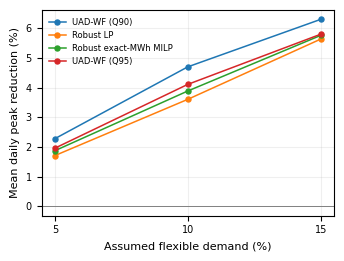

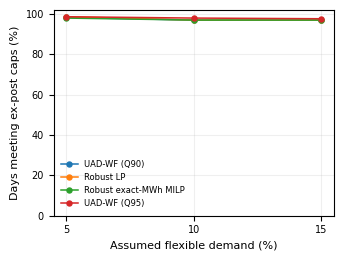

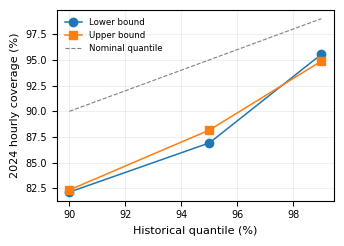

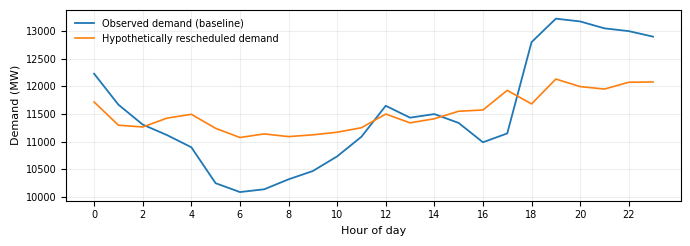

Illustrative day selected by median BASELINE peak (not algorithm performance): 2024-08-26
Figure exports saved in 600-DPI PNG and vector PDF.


In [ ]:
from matplotlib.ticker import MaxNLocator
plt.rcParams.update({'font.size':8, 'axes.titlesize':9, 'axes.labelsize':8,
                     'xtick.labelsize':7, 'ytick.labelsize':7, 'legend.fontsize':7,
                     'pdf.fonttype':42, 'ps.fonttype':42, 'savefig.bbox':'tight'})

PLOT_METHODS=[('WaterfillQ90','UAD-WF (Q90)'),
              ('BudgetRobustLPQ90','Robust LP'),
              ('UnrestrictedExactRobustMILPQ90','Robust exact-MWh MILP'),
              ('WaterfillQ95','UAD-WF (Q95)')]

def save_fig(fig,stem):
    fig.savefig(OUT_DIR / (stem+'.png'),dpi=600,bbox_inches='tight',pad_inches=.10)
    fig.savefig(OUT_DIR / (stem+'.pdf'),bbox_inches='tight',pad_inches=.10)
    plt.show()
    plt.close(fig)

fig,ax=plt.subplots(figsize=(3.48,2.65))
for method,label in PLOT_METHODS:
    rows=SUMMARY.loc[SUMMARY.method.eq(method)].sort_values('alpha')
    ax.plot(rows.alpha*100,rows.mean_peak_reduction_pct,marker='o',markersize=3.6,lw=1.1,label=label)
ax.axhline(0,color='gray',lw=.7)
ax.set(xlabel='Assumed flexible demand (%)',ylabel='Mean daily peak reduction (%)')
ax.set_xticks([5,10,15]);ax.grid(alpha=.2)
ax.legend(loc='best',fontsize=6.0,frameon=False)
fig.tight_layout()
save_fig(fig,'final_fig_peak_reduction_2024')

fig,ax=plt.subplots(figsize=(3.48,2.65))
for method,label in PLOT_METHODS:
    rows=SUMMARY.loc[SUMMARY.method.eq(method)].sort_values('alpha')
    ax.plot(rows.alpha*100,rows.feasible_days_pct,marker='o',markersize=3.6,lw=1.1,label=label)
ax.set(xlabel='Assumed flexible demand (%)',ylabel='Days meeting ex-post caps (%)',ylim=(0,102))
ax.set_xticks([5,10,15]);ax.grid(alpha=.2)
ax.legend(loc='best',fontsize=6.0,frameon=False)
fig.tight_layout()
save_fig(fig,'final_fig_feasibility_2024')

fig,ax=plt.subplots(figsize=(3.48,2.5))
quantiles=np.array(sorted(MARGINS.keys()))
cover_sorted=COVERAGE.set_index('quantile').loc[quantiles]
ax.plot(100*quantiles,cover_sorted.lower_coverage_pct,marker='o',lw=1.1,label='Lower bound')
ax.plot(100*quantiles,cover_sorted.upper_coverage_pct,marker='s',lw=1.1,label='Upper bound')
ax.plot(100*quantiles,100*quantiles,ls='--',lw=.8,color='gray',label='Nominal quantile')
ax.set(xlabel='Historical quantile (%)',ylabel='2024 hourly coverage (%)')
ax.grid(alpha=.2);ax.legend(frameon=False,fontsize=6.2)
fig.tight_layout()
save_fig(fig,'final_fig_margin_coverage_2024')

# Select the 2024 day closest to the median observed daily peak, WITHOUT selecting on improvement.
case_peak=np.array([float(c['actual'].max()) for c in CASES])
selected_day=CASES[int(np.argmin(np.abs(case_peak-np.median(case_peak))))]
sel_day_str=selected_day['date'].strftime('%Y-%m-%d')
sel_forecast=selected_day['forecast'];sel_actual=selected_day['actual']
sel_under=MARGINS[.90]['under'];sel_over=MARGINS[.90]['over']
sel_caps,_=conservative_caps(sel_forecast,.15,sel_under,sel_over)
sel_delta=waterfill_shift(sel_forecast+sel_under,sel_caps)
fig,ax=plt.subplots(figsize=(6.95,2.50))
hours=np.arange(24)
ax.plot(hours,sel_actual,lw=1.3,label='Observed demand (baseline)')
ax.plot(hours,sel_actual+sel_delta,lw=1.2,label='Hypothetically rescheduled demand')
ax.set(xlabel='Hour of day',ylabel='Demand (MW)',xticks=range(0,24,2))
ax.grid(alpha=.20);ax.legend(loc='best',frameon=False)
fig.tight_layout()
save_fig(fig,'final_fig_daily_profile_2024')
print('Illustrative day selected by median BASELINE peak (not algorithm performance):',sel_day_str)
print('Figure exports saved in 600-DPI PNG and vector PDF.')


## 16. Export the frozen protocol, tables and reproducibility archive

Save every result with the original data SHA-256, chronological split and fixed algorithm settings. Include a concise Markdown results memo with comparable 2024 outcomes for the manuscript. Zip output data and figures for archival use, but do not claim external deployment, verified load-shedding reductions or a mathematically novel water-filling mechanism.


In [ ]:
PROTOCOL={
  'paper_title':'An Intelligent Demand-Aware Optimization Framework for Peak Load Management and Load-Shedding Mitigation in Smart Grids',
  'protocol':'Fixed Phase 5 algorithm, new chronological 2024 temporal evaluation',
  'run_id':RUN_ID,
  'dataset':'PGCB Hourly Generation Dataset (Bangladesh), UCI #1175, DOI 10.24432/C59P6V, CC BY 4.0',
  'source_workbook_sha256':SOURCE_SHA256,
  'source_input_filename':DATASET_FILENAME,
  'training':'eligible records through 2022-06-30',
  'calibration':'2022-07-01 through 2022-12-31',
  'development':'2023, inspected in earlier phases; not used to update fixed model in this notebook',
  'evaluation':'2024-01-01 through 2024-12-31, later chronological period',
  'n_evaluation_days':len(CASES),
  'forecasting':{'model':'Ridge','alpha':100.0,'features':FEATURES,'imputation':'training medians',
                 'scaling':'training standardized features','eval_mae_mw':evaluation_mae,
                 'eval_rmse_mw':evaluation_rmse,'eval_mape_pct':evaluation_mape},
  'data_quality':DATA_QUALITY,
  'flexibility_assumptions':[.05,.10,.15],
  'uncertainty_quantiles':[.90,.95,.99],
  'hour_margin_weight':.5,
  'data_inclusion_floor_mw':DOMAIN_FLOOR_MW,
  'milp':{'time_limit_seconds':MIP_TIME_LIMIT_SECONDS,'mip_rel_gap':MIP_RELATIVE_GAP,
          'independent_hours':True,'exact_candidate_mwh':True,'accepted_solver_status':0},
  'algorithms':list(METHODS),
  'main_candidate':'WaterfillQ90 (manuscript working label UAD-WF Q90)',
  'resampling':{'unit':'calendar-week cluster','replicates':BOOTSTRAP_REPLICATES,'seed':SEED},
  'figure_export':{'raster_dpi':600,'vector_pdf':True},
  'limitations':[
    'Hypothetical demand flexibility, not recorded appliance-level controllability.',
    'Realized post-scheduling demands are counterfactual simulations; no physical load shifting demonstrated.',
    'No verified avoided blackouts/load shedding, operating costs, physical energy savings or emissions.',
    'Daily MWh is conserved: load is rescheduled, not reduced in total.',
    'Ridge model and water-fill candidate are established ideas; mathematical novelty not yet demonstrated.',
    'The sample filters out off-hour/duplicate/partial days; it is not the full national operating history.',
    'Historical quantiles do not guarantee uncertainty coverage after distribution shift.',
    'The journal paper forecasting results use a different feature set and protocol: raw MAPE values cannot be claimed directly comparable.',
    'The 2024 temporal evaluation is later than the inspected 2023 period but broader hyperparameter exploration could still affect conclusions.'
  ],
  'versions':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,
              'scipy':scipy.__version__,'sklearn':sklearn.__version__},
}
(OUT_DIR/'final_validation_protocol.json').write_text(json.dumps(PROTOCOL,indent=2))

# Write a compact manuscript-table starting point directly from actual output, not rounded memory numbers.
primary=['WaterfillQ90','BudgetRobustLPQ90','UnrestrictedExactRobustMILPQ90',
         'UnrestrictedExactNominalMILPQ90','WaterfillQ95','WaterfillQ99']
main=SUMMARY.loc[SUMMARY.alpha.eq(.15)&SUMMARY.method.isin(primary)].copy()
main['method']=pd.Categorical(main.method,categories=primary,ordered=True)
main=main.sort_values('method')
caption='2024 temporal validation; 15% assumed hourly flexibility; all results are counterfactual simulations.'
lines=['# IEEE paper: 2024 validation — verified numerical summaries','',caption,'',
       'Method | Mean peak reduction (%) | Feasible days (%) | Mean moved MWh/day | Worse-peak days (%)',
       '---|---:|---:|---:|---:']
for _,r in main.iterrows():
    lines.append(f"{r['method']} | {r['mean_peak_reduction_pct']:.3f} | {r['feasible_days_pct']:.2f} | "
                 f"{r['mean_moved_energy_mwh']:.1f} | {r['worse_peak_days_pct']:.2f}")
lines.extend(['',f'Eligible 2024 days: {len(CASES)}',
              f"Forecasting 2024: Ridge MAE {evaluation_mae:.2f} MW; RMSE {evaluation_rmse:.2f} MW; MAPE {evaluation_mape:.2f}%.",
              '', 'IMPORTANT: External literature uses different forecasting protocols. Do not label this table as direct MAPE superiority.',
              'No verified real-world load-shedding mitigation or physical demand-response capability is demonstrated.',
              'All shifted MWh are simulated and conserved within each evaluated day.'])
(OUT_DIR/'final_manuscript_results_2024.md').write_text('\n'.join(lines)+'\n',encoding='utf-8')

archive_path=OUT_DIR/'final_validation_outputs_2024.zip'
with zipfile.ZipFile(archive_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for path in sorted(OUT_DIR.iterdir()):
        if path.is_file() and path!=archive_path:
            z.write(path,arcname=path.name)
required=['final_summary_2024.csv','final_daily_results_2024.csv',
          'final_weekly_bootstrap_2024.csv','final_validation_protocol.json',
          'final_manuscript_results_2024.md','final_validation_outputs_2024.zip',
          'final_fig_peak_reduction_2024.png','final_fig_peak_reduction_2024.pdf']
assert all((OUT_DIR/file).exists() for file in required)
print('Final 2024 validation complete. Saved to:',OUT_DIR)
print((OUT_DIR/'final_manuscript_results_2024.md').read_text())


Final 2024 validation complete. Saved to: /content/drive/MyDrive/PGCB_Demand_Optimization/runs/ieee_final_2024_20261108T042536Z_4eecbb
# IEEE paper: 2024 validation — verified numerical summaries

2024 temporal validation; 15% assumed hourly flexibility; all results are counterfactual simulations.

Method | Mean peak reduction (%) | Feasible days (%) | Mean moved MWh/day | Worse-peak days (%)
---|---:|---:|---:|---:
WaterfillQ90 | 6.297 | 97.00 | 7301.5 | 4.00
BudgetRobustLPQ90 | 5.632 | 97.00 | 6327.9 | 3.67
UnrestrictedExactRobustMILPQ90 | 5.756 | 97.00 | 7301.5 | 4.33
UnrestrictedExactNominalMILPQ90 | 5.782 | 97.00 | 7301.5 | 4.33
WaterfillQ95 | 5.796 | 97.67 | 6392.7 | 4.33
WaterfillQ99 | 4.618 | 98.00 | 4426.0 | 2.67

Eligible 2024 days: 300
Forecasting 2024: Ridge MAE 695.71 MW; RMSE 1097.13 MW; MAPE 7.21%.

IMPORTANT: External literature uses different forecasting protocols. Do not label this table as direct MAPE superiority.
No verified real-world load-shedding mitigation or ph